# Notebook 05 (4-layer benchmark) — Architecture Comparison, Seed Analysis and Selection

**Track A extension · Soccer Event Transformer · Identity × Context project**

| Item | Content |
|---|---|
| **Research question (benchmark)** | How does the 4-layer Transformer family behave when the number of heads and the context length are varied, and which 4-layer configuration should be carried forward to final evaluation? |
| **Purpose of this notebook** | Analyse the 27 runs of benchmark notebook 04; compare them with the existing Track A results; identify the best predictive, most stable, smallest adequate and most MI-accessible 4-layer configurations; select one configuration for final evaluation; assess separately whether the evidence supports replacing the existing 2-layer Track A model. |
| **Relation to Track A notebook 05** | The original notebook 05 made four staged decisions (player threshold, depth, heads, context). This notebook reports those decisions unchanged (Section 2) and analyses the 4-layer grid with the same statistical procedure. |
| **Test data** | Not used. The selection is made on validation data only and is recorded before the test split is used in benchmark notebook 06. |


In [1]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every 4-layer benchmark notebook)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
import hashlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")      # "full" = research runs, "smoke" = code check only
assert RUN_MODE in ("full", "smoke")
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Existing Track A outputs. These are read, never written.
EXISTING_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
EXISTING_RUNS_DIR = EXISTING_DIR / "runs"
EXISTING_RESULTS_DIR = EXISTING_DIR / "results"
EXISTING_FROZEN_CONFIG = EXISTING_DIR / "config" / "frozen_config.json"
EXISTING_BASELINE_FILE = PROJECT_DIR / "results" / "baselines_validation.json"

# All outputs of the 4-layer benchmark are written below BENCH_DIR only.
BENCH_DIR = EXISTING_DIR / "benchmarks" / "track_a_4layer"
RUNS_DIR = BENCH_DIR / "runs"
RESULTS_DIR = BENCH_DIR / "results"
FIGURES_DIR = BENCH_DIR / "figures"
CONFIG_DIR = BENCH_DIR / "config"
MANIFEST_DIR = BENCH_DIR / "manifests"
LOG_DIR = BENCH_DIR / "logs"
for folder in [RUNS_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MANIFEST_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = MANIFEST_DIR / "experiment_manifest.jsonl"

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("Existing Track A outputs (read-only):", EXISTING_DIR)
print("Benchmark outputs:", BENCH_DIR)

Mounted at /content/drive
Colab: True | RUN_MODE: full
Existing Track A outputs (read-only): /content/drive/MyDrive/soccer_mi/track_a
Benchmark outputs: /content/drive/MyDrive/soccer_mi/track_a/benchmarks/track_a_4layer


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import importlib
from scipy import stats

# The Track A modules are imported, never rewritten. The benchmark therefore runs on
# exactly the code that produced the existing Track A results.
import src.data as data
import src.batching as batching
import src.metrics as metrics
import src.model as model_module
import src.mlp_baseline as mlp_baseline
import src.training as training
import src.analysis as analysis
for module in [data, batching, metrics, model_module, mlp_baseline, training, analysis]:
    importlib.reload(module)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if RUN_MODE == "full" and DEVICE != "cuda":
    raise RuntimeError("BLOCKED: full-mode training requires a GPU. In Colab: Runtime > Change runtime type > GPU.")

events = pd.read_parquet(ARTIFACTS_DIR / "events_prepared.parquet")
targets = events["action_id"].to_numpy().astype("int64")
match_ids = events["match_id"].to_numpy()

with open(EXISTING_FROZEN_CONFIG) as handle:
    EXISTING_FROZEN = json.load(handle)
with open(EXISTING_RESULTS_DIR / "04_selected_hyperparameters.json") as handle:
    EXISTING_HYPERPARAMETERS = json.load(handle)

# Settings shared by every benchmark run: taken from the frozen Track A configuration.
ENCODING = EXISTING_FROZEN["encoding"]
POSSESSION_FEATURES = EXISTING_FROZEN["possession_features"]
STRIDE = EXISTING_FROZEN["stride"]
LEARNING_RATE = EXISTING_HYPERPARAMETERS["learning_rate"]
WEIGHT_DECAY = EXISTING_HYPERPARAMETERS["weight_decay"]
EPOCH_BUDGET = EXISTING_HYPERPARAMETERS["epoch_budget"]
D_MODEL = 128
D_FF = 512


def transformer_config(seed, n_layers, n_heads, context_length, use_groups=None):
    """Run configuration in exactly the format used by Track A notebooks 04-06."""
    model = {"n_layers": n_layers, "n_heads": n_heads, "d_model": D_MODEL, "d_ff": D_FF}
    if use_groups is not None:
        model["use_groups"] = list(use_groups)
    config = {"model_type": "transformer", "encoding": ENCODING, "possession_features": POSSESSION_FEATURES,
              "context_length": context_length, "stride": STRIDE, "seed": seed, "model": model,
              "training": {"learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY, "max_epochs": EPOCH_BUDGET}}
    return config


def config_id(n_layers, n_heads, context_length, seed=None):
    """Readable identifier, e.g. 4L_2H_K32_seed0."""
    label = f"{n_layers}L_{n_heads}H_K{context_length}"
    if seed is not None:
        label = label + f"_seed{seed}"
    return label


def bundle_for(context_length, encoding=None):
    if encoding is None:
        encoding = ENCODING
    return training.prepare_data(events, ARTIFACTS_DIR, encoding, POSSESSION_FEATURES, context_length, STRIDE,
                                 DEVICE, RUN_MODE)


def benchmark_run_dir(config):
    return RUNS_DIR / training.run_name_for(config)


def existing_run_dir(config):
    return EXISTING_RUNS_DIR / training.run_name_for(config)


def train_benchmark_run(config, keep_every_epoch=False):
    """Train (or load, if already finished) one benchmark run. Output goes to the benchmark folder only."""
    result = training.train_run(config, bundle_for(config["context_length"]), RUNS_DIR, MANIFEST_PATH,
                                keep_every_epoch=keep_every_epoch)
    return RUNS_DIR / result["run_name"]


def run_record(run_dir, label, source):
    """One row of seed-level results from a finished run folder."""
    result = analysis.load_final_results(run_dir)
    config = result["run_config"]
    val = result["val_metrics"]
    return {"source": source, "label": label,
            "layers": config["model"]["n_layers"], "heads": config["model"]["n_heads"],
            "d_head": config["model"]["d_model"] // config["model"]["n_heads"],
            "d_model": config["model"]["d_model"], "d_ff": config["model"]["d_ff"],
            "K": config["context_length"], "seed": config["seed"],
            "parameters": result["parameter_counts"]["total"],
            "best_epoch": result["best_epoch"], "epochs_run": result["epochs_run"],
            "val_nll": val["nll"], "val_accuracy": val["accuracy"], "val_macro_f1": val["macro_f1"],
            "val_top3": val["top3_accuracy"], "val_top5": val["top5_accuracy"], "val_ece": val["ece"],
            "train_nll": result["train_nll"], "training_minutes": result["runtime_seconds"] / 60,
            "run_dir": str(run_dir)}


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while True:
            block = handle.read(1024 * 1024)
            if not block:
                break
            digest.update(block)
    return digest.hexdigest()


print(f"Settings inherited from Track A: encoding {ENCODING}, possession features {POSSESSION_FEATURES}, "
      f"stride {STRIDE}, learning rate {LEARNING_RATE:g}, weight decay {WEIGHT_DECAY:g}, epoch budget {EPOCH_BUDGET}")
print("Device:", DEVICE)

Settings inherited from Track A: encoding T300, possession features pre_action, stride 8, learning rate 0.0003, weight decay 0.1, epoch budget 30
Device: cuda


## 1. Metrics and statistical terms

| Term | Definition and role in this analysis |
|---|---|
| **NLL (negative log-likelihood)** | The mean of −log p(observed action) over validation events, in nats. It is identical to the cross-entropy loss used in training. NLL evaluates the whole predicted distribution: it rewards probability placed on the action that occurred and penalises confident errors. It is the primary metric because the model is used as a probability model and the later mechanistic analysis uses its log-probabilities. |
| **Accuracy** | The share of events whose most probable class is the observed class. It evaluates only the argmax and is dominated by the three most frequent classes. |
| **Macro-F1** | The unweighted mean of the per-class F1 scores (F1 is the harmonic mean of precision and recall for one class). Each of the 15 classes counts equally, so the metric reflects performance on rare actions. |
| **Top-k accuracy** | The share of events whose observed class is among the k most probable classes (k = 3, 5). It indicates whether the observed action remains among the model's plausible alternatives. |
| **Calibration and ECE** | A model is calibrated when its stated confidence equals its observed accuracy. The expected calibration error (ECE) groups events into 15 confidence bins and averages the absolute gap between mean confidence and accuracy, weighted by bin size. |
| **Seed variance** | Variation of a metric across training runs that differ only in the random seed. It measures how much of a difference between configurations could arise by chance in training. |
| **Confidence interval (CI)** | For a configuration mean over n seeds, the 95% t-interval mean ± t(0.975, n−1) · SD / √n. With n = 3, t = 4.30, so the interval is wide; it reflects the small number of seeds, not an error in the procedure. For differences between configurations, the Track A match-level bootstrap interval is used (Section 3). |
| **Validation versus test** | All comparisons and the selection in this notebook use the validation split (35 matches). The test split (35 other matches) is used only in benchmark notebook 06, after the selection is frozen. |
| **Head dimension, parameter count, context window** | Defined in benchmark notebook 04, Section 1. |

## 2. Decisions inherited from Track A notebook 05

The benchmark keeps every decision of the Track A architecture study except the architecture itself. This section reproduces those decisions from the saved Track A result files so that the benchmark can be read without the original notebook.

### 2.1 Player threshold: T300 selected over T100

Track A notebook 05 compared three player encodings on the base configuration (4 layers, 4 heads, K = 32, seeds 0–2):

* **T300** gives a player a dedicated embedding if the player has at least 300 training events;
* **T100** uses a threshold of 100 training events;
* **T100-shuffled** uses T100, but permutes the player index among band players (100–299 training events) of the same split and role, which removes player-specific information while keeping the number of embeddings and their usage.

T100 was to be adopted only if all five pre-registered conditions held. The table below reproduces the recorded comparisons.

In [3]:
with open(EXISTING_RESULTS_DIR / "05_stage1_threshold.json") as handle:
    stage1 = json.load(handle)
stage1_rows = []
for name, comparison in stage1["comparisons"].items():
    stage1_rows.append({"comparison (A vs B)": name, "events": comparison["n_events"],
                        "NLL A": comparison["nll_a_mean"], "NLL B": comparison["nll_b_mean"],
                        "A - B": comparison["difference_a_minus_b"],
                        "95% CI": f"[{comparison['difference_ci_low']:+.4f}, {comparison['difference_ci_high']:+.4f}]",
                        "seeds separated": comparison["seeds_completely_separated"],
                        "A better beyond noise": comparison["a_better_beyond_noise"]})
stage1_table = pd.DataFrame(stage1_rows).set_index("comparison (A vs B)")
print("Per-player gain correlations between seed pairs:", [round(value, 3) for value in stage1["gain_correlations"]],
      f"| mean {stage1['mean_gain_correlation']:.3f} | band players with >= 30 validation events: {stage1['eligible_players']}")
print("Conditions:")
for condition, passed in stage1["conditions"].items():
    print(f"  {'PASS' if passed else 'FAIL'}  {condition}")
print("Stage 1 decision:", stage1["decision"])
stage1_table.round(4)

Per-player gain correlations between seed pairs: [0.388, 0.328, 0.233] | mean 0.317 | band players with >= 30 validation events: 221
Conditions:
  FAIL  1. T100 beats T300 on band
  PASS  2. T100 beats T100-shuffled on band
  FAIL  3. T300 does not beat T100 on >=300 players
  FAIL  4. T300 does not beat T100 overall
  PASS  5. per-player gains stable (mean Spearman >= 0.3, PROVISIONAL)
Stage 1 decision: T300


,events,NLL A,NLL B,A - B,95% CI,seeds separated,A better beyond noise
comparison (A vs B),,,,,,,
"1. T100 vs T300, band 100-299",20693,0.9417,0.9142,0.0275,"[+0.0215, +0.0332]",False,False
"2. T100 vs T100-shuffled, band 100-299",20693,0.9417,0.9526,-0.0109,"[-0.0168, -0.0044]",True,True
"3. T300 vs T100, players >= 300",13891,0.9077,0.9183,-0.0106,"[-0.0158, -0.0062]",True,True
"4. T300 vs T100, all events",68003,0.9146,0.9303,-0.0158,"[-0.0187, -0.0129]",True,True


**Result.** T100 achieved lower validation NLL than T100-shuffled on events of band players (100–299 training events): 0.9417 against 0.9526, a difference of −0.0109 nats (95% CI −0.0168 to −0.0044), with complete separation of the three seeds. The additional player identities therefore contain predictive information that is not explained by the larger number of embeddings alone.

T100 nevertheless failed three of the five conditions. On the band events themselves, T100 was worse than T300 (0.9417 against 0.9142), because under T300 these players share the fixed "no identity" vector and the model relies on role and context. T300 was better beyond noise on players with at least 300 training events (−0.0106 nats) and on all validation events (−0.0158 nats). The train–validation NLL gap on band events was 0.111 for T100 against 0.065 for T300, which indicates that the dedicated band embeddings were fitted to the training matches more than they generalised. The per-player stability condition passed (mean Spearman correlation 0.317 against the conventional value of 0.3). Under the pre-registered rule, T300 was retained.

The result shows that player identity carries information in this setting, while the additional 1,341 embeddings under T100 reduced overall predictive performance. The benchmark uses T300 unchanged.

### 2.2 Depth, heads and context in Track A

In [4]:
stage_tables = {}
for stage_file, stage_name in [("05_stage2_depth.csv", "depth (heads 4, K = 32)"),
                               ("05_stage3_heads.csv", "heads (2 layers, K = 32)"),
                               ("05_stage4_context.csv", "context (2 layers, 2 heads)")]:
    table = pd.read_csv(EXISTING_RESULTS_DIR / stage_file)
    table.insert(0, "stage", stage_name)
    stage_tables[stage_name] = table
print("Frozen Track A configuration:", json.dumps({"encoding": EXISTING_FROZEN["encoding"],
      "context_length": EXISTING_FROZEN["context_length"], "model": EXISTING_FROZEN["model"],
      "decisions": EXISTING_FROZEN["decisions"]}))
pd.concat(stage_tables.values(), ignore_index=True)

Frozen Track A configuration: {"encoding": "T300", "context_length": 16, "model": {"n_layers": 2, "n_heads": 2, "d_model": 128, "d_ff": 512}, "decisions": {"stage1_threshold": "T300", "stage2_depth": "2 layers", "stage3_heads": "2 heads x 64", "stage4_context": "K=16"}}


,stage,candidate,mean val NLL,is best,best beats it beyond noise,best - candidate (CI),seeds separated
0,"depth (heads 4, K = 32)",2 layers,0.9165,False,False,"-0.0019 [-0.0037, -0.0002]",False
1,"depth (heads 4, K = 32)",4 layers,0.9146,True,False,NaN,NaN
2,"heads (2 layers, K = 32)",2 heads x 64,0.9166,False,False,"-0.0001 [-0.0021, +0.0018]",False
3,"heads (2 layers, K = 32)",4 heads x 32,0.9165,True,False,NaN,NaN
4,"heads (2 layers, K = 32)",8 heads x 16,0.9196,False,False,"-0.0031 [-0.0048, -0.0014]",False
5,"context (2 layers, 2 heads)",K=16,0.9074,True,False,NaN,NaN
6,"context (2 layers, 2 heads)",K=32,0.9166,False,True,"-0.0092 [-0.0108, -0.0077]",True
7,"context (2 layers, 2 heads)",K=64,0.9299,False,True,"-0.0225 [-0.0251, -0.0200]",True


In Track A the 4-layer model (4 heads, K = 32) reached a mean validation NLL of 0.9146 against 0.9165 for 2 layers. The bootstrap interval of the difference excluded zero, but the per-seed results overlapped, so the difference did not meet the decision rule and the smaller model was retained. The head count at 2 layers changed NLL by at most 0.003 nats, and K = 16 was better than K = 32 and K = 64 beyond noise. The frozen Track A model is 2 layers × 2 heads × K = 16 with encoding T300.

The staged Track A design tested heads and context only at 2 layers, and depth only at 4 heads and K = 32. The 4-layer benchmark fills this gap for the 4-layer family.

## 3. Statistical procedure

Two kinds of comparison are reported.

1. **Configuration summaries.** For each configuration: the per-seed values, the mean, the standard deviation (SD) and the 95% t-interval of the mean.
2. **Pairwise comparisons.** The Track A decision rule (Track A notebook 04, Section 2.5) is applied unchanged. Configuration A is better than B beyond noise if (i) the 95% match-level bootstrap confidence interval of the NLL difference A − B, computed on per-event NLL averaged over seeds, lies entirely below zero, and (ii) every seed of A has lower validation NLL than every seed of B. The rule is a convention of this study and is used unchanged. When only criterion (i) holds, the difference is reported as not meeting the rule and the comparison is described as inconclusive.

Because both configurations are evaluated on the same 68,003 validation events, the bootstrap interval is a paired comparison. Pairwise results are reported as the gap between the higher and the lower mean NLL (a non-negative number) with the 95% interval of that gap; an interval whose lower end is above zero corresponds to criterion (i). Many pairwise comparisons are reported; no correction for multiple comparisons is applied, so an individual interval that barely excludes zero is not treated as strong evidence.

In [5]:
GRID_HEADS = [2, 4, 8]
GRID_CONTEXT = [16, 32, 64]
SCREENING_SEEDS = [0, 1, 2]


def benchmark_runs(n_heads, context_length, seeds=SCREENING_SEEDS):
    run_dirs = []
    for seed in seeds:
        run_dirs.append(benchmark_run_dir(transformer_config(seed, 4, n_heads, context_length)))
    return run_dirs


def existing_runs(n_layers, n_heads, context_length, seeds=SCREENING_SEEDS):
    """Existing Track A runs of one configuration; only runs that exist are returned."""
    run_dirs = []
    for seed in seeds:
        run_dir = existing_run_dir(transformer_config(seed, n_layers, n_heads, context_length))
        if (run_dir / "final_results.json").exists():
            run_dirs.append(run_dir)
    return run_dirs


def summarise(run_dirs, label, source):
    """Configuration summary: mean, SD and 95% t-interval of validation NLL plus mean secondary metrics."""
    records = []
    for run_dir in run_dirs:
        records.append(run_record(run_dir, label, source))
    table = pd.DataFrame(records)
    n_seeds = len(table)
    mean_nll = table["val_nll"].mean()
    sd_nll = table["val_nll"].std(ddof=1) if n_seeds > 1 else np.nan
    half_width = stats.t.ppf(0.975, n_seeds - 1) * sd_nll / np.sqrt(n_seeds) if n_seeds > 1 else np.nan
    first = table.iloc[0]
    return {"source": source, "configuration": label, "layers": first["layers"], "heads": first["heads"],
            "d_head": first["d_head"], "d_model": first["d_model"], "d_ff": first["d_ff"], "K": first["K"],
            "parameters": first["parameters"], "seeds": n_seeds, "seed list": list(table["seed"]),
            "mean val NLL": mean_nll, "NLL SD": sd_nll,
            "NLL 95% CI low": mean_nll - half_width, "NLL 95% CI high": mean_nll + half_width,
            "per-seed val NLL": [round(v, 4) for v in table["val_nll"]],
            "val accuracy": table["val_accuracy"].mean(), "val macro-F1": table["val_macro_f1"].mean(),
            "val top-3": table["val_top3"].mean(), "val top-5": table["val_top5"].mean(),
            "val ECE": table["val_ece"].mean(), "mean best epoch": table["best_epoch"].mean(),
            "training minutes per run": table["training_minutes"].mean()}


def compare_pair(label_a, runs_a, label_b, runs_b):
    """Track A decision rule, applied with the lower-NLL configuration as A."""
    first = analysis.compare_conditions(runs_a, runs_b, targets, match_ids)
    if first["nll_a_mean"] <= first["nll_b_mean"]:
        result = first
        lower, higher = label_a, label_b
    else:
        result = analysis.compare_conditions(runs_b, runs_a, targets, match_ids)
        lower, higher = label_b, label_a
    result["lower"] = lower
    result["higher"] = higher
    # gap = NLL(higher) - NLL(lower) >= 0, with its interval in the same direction
    result["gap"] = -result["difference_a_minus_b"]
    result["gap_ci_low"] = -result["difference_ci_high"]
    result["gap_ci_high"] = -result["difference_ci_low"]
    return result


def describe(result):
    """Formal one-paragraph description of a pairwise comparison."""
    text = (f"{result['lower']} had a lower mean validation NLL than {result['higher']} by {result['gap']:.4f} nats "
            f"(95% bootstrap CI of the gap {result['gap_ci_low']:.4f} to {result['gap_ci_high']:.4f}). ")
    if result["a_better_beyond_noise"]:
        text += "Both criteria of the decision rule were met, so the difference is treated as beyond noise."
    elif result["gap_ci_low"] > 0:
        text += ("The interval excludes zero, but the per-seed results overlapped, so the difference does not meet the "
                 "decision rule; the comparison is inconclusive.")
    else:
        text += "The interval includes zero; the experiment does not provide evidence for a difference."
    return text

## 4. Results of the 4-layer grid

### 4.1 Seed-level results

In [6]:
seed_rows = []
for n_heads in GRID_HEADS:
    for context_length in GRID_CONTEXT:
        for run_dir, seed in zip(benchmark_runs(n_heads, context_length), SCREENING_SEEDS):
            record = run_record(run_dir, config_id(4, n_heads, context_length), "4-layer benchmark")
            record["config_id"] = config_id(4, n_heads, context_length, seed)
            seed_rows.append(record)
seed_table = pd.DataFrame(seed_rows)
seed_table[["config_id", "best_epoch", "val_nll", "val_accuracy", "val_macro_f1", "val_top3", "val_top5",
            "val_ece", "training_minutes"]].round(4)

,config_id,best_epoch,val_nll,val_accuracy,val_macro_f1,val_top3,val_top5,val_ece,training_minutes
0,4L_2H_K16_seed0,8,0.9037,0.6213,0.5670,0.9478,0.9941,0.0175,2.0467
1,4L_2H_K16_seed1,8,0.9017,0.6241,0.5593,0.9483,0.9944,0.0221,2.0181
2,4L_2H_K16_seed2,9,0.9021,0.6244,0.5673,0.9490,0.9945,0.0286,2.1799
3,4L_2H_K32_seed0,5,0.9114,0.6194,0.5385,0.9464,0.9940,0.0285,1.5961
4,4L_2H_K32_seed1,5,0.9119,0.6179,0.5454,0.9467,0.9941,0.0169,1.5978
5,4L_2H_K32_seed2,7,0.9135,0.6183,0.5533,0.9474,0.9943,0.0369,1.9304
6,4L_2H_K64_seed0,4,0.9341,0.6093,0.5441,0.9444,0.9937,0.0193,2.2892
7,4L_2H_K64_seed1,4,0.9328,0.6091,0.5488,0.9446,0.9936,0.0107,2.3024
8,4L_2H_K64_seed2,4,0.9288,0.6163,0.5394,0.9455,0.9936,0.0393,2.2961
9,4L_4H_K16_seed0,6,0.9054,0.6209,0.5582,0.9485,0.9942,0.0135,1.7304


### 4.2 Configuration summaries

The configuration 4L_4H_K32 in this table is the benchmark re-run of the original Track A 4-layer configuration (benchmark notebook 04, Section 5). The value recorded in Track A notebook 05 (0.9146) is listed separately in the consolidated table of Section 6 and is not used in the within-benchmark comparisons.

In [7]:
grid_summaries = []
for n_heads in GRID_HEADS:
    for context_length in GRID_CONTEXT:
        label = config_id(4, n_heads, context_length)
        if n_heads == 4 and context_length == 32:
            label = label + " (re-run of original)"
        grid_summaries.append(summarise(benchmark_runs(n_heads, context_length), label, "4-layer benchmark"))
grid_summary = pd.DataFrame(grid_summaries)
grid_summary.to_csv(RESULTS_DIR / "05_4L_grid_summary.csv", index=False)
grid_summary[["configuration", "parameters", "mean val NLL", "NLL SD", "NLL 95% CI low", "NLL 95% CI high",
              "per-seed val NLL", "val accuracy", "val macro-F1", "val top-3", "val top-5", "val ECE",
              "mean best epoch", "training minutes per run"]].round(4)

,configuration,parameters,mean val NLL,NLL SD,NLL 95% CI low,NLL 95% CI high,per-seed val NLL,val accuracy,val macro-F1,val top-3,val top-5,val ECE,mean best epoch,training minutes per run
0,4L_2H_K16,911119,0.9025,0.0010,0.8999,0.9051,"[0.9037, 0.9017, 0.9021]",0.6233,0.5645,0.9484,0.9943,0.0227,8.3333,2.0816
1,4L_2H_K32,913167,0.9122,0.0011,0.9096,0.9149,"[0.9114, 0.9119, 0.9135]",0.6185,0.5457,0.9469,0.9942,0.0275,5.6667,1.7081
2,4L_2H_K64,917263,0.9319,0.0028,0.9250,0.9388,"[0.9341, 0.9328, 0.9288]",0.6116,0.5441,0.9448,0.9936,0.0231,4.0000,2.2959
3,4L_4H_K16,911119,0.9040,0.0012,0.9009,0.9070,"[0.9054, 0.9032, 0.9034]",0.6224,0.5596,0.9480,0.9942,0.0192,8.0000,2.0421
4,4L_4H_K32 (re-run of original),913167,0.9146,0.0052,0.9017,0.9274,"[0.9089, 0.9158, 0.919]",0.6187,0.5490,0.9465,0.9942,0.0257,5.6667,1.7463
5,4L_4H_K64,917263,0.9307,0.0004,0.9297,0.9316,"[0.9309, 0.9308, 0.9302]",0.6137,0.5449,0.9447,0.9934,0.0253,3.6667,2.3194
6,4L_8H_K16,911119,0.9058,0.0040,0.8959,0.9158,"[0.9104, 0.9041, 0.903]",0.6212,0.5588,0.9475,0.9942,0.0204,8.0000,2.0412
7,4L_8H_K32,913167,0.9154,0.0013,0.9122,0.9186,"[0.9139, 0.916, 0.9163]",0.6172,0.5494,0.9461,0.9941,0.0171,5.3333,1.8538
8,4L_8H_K64,917263,0.9316,0.0009,0.9294,0.9338,"[0.9309, 0.9313, 0.9326]",0.6111,0.5476,0.9448,0.9936,0.0201,3.6667,2.6519


**Observation.** The mean validation NLL ranges from 0.9025 (4L_2H_K16) to 0.9319 (4L_2H_K64). The three K = 16 configurations have the lowest means (0.9025, 0.9040, 0.9058), followed by K = 32 (0.9122–0.9154) and K = 64 (0.9307–0.9319). Accuracy and macro-F1 follow the same order: the K = 16 configurations reach accuracy 0.621–0.623 and macro-F1 0.559–0.565, against 0.611–0.614 and 0.544–0.548 at K = 64. Most configurations have a seed SD of 0.0004–0.0028; the exceptions are 4L_8H_K16 (0.0040) and the original 4L_4H_K32 (0.0052).

### 4.3 Head-count comparison within each context length

For each context length, every head count is compared with the head count of lowest mean NLL at that context length.

In [8]:
head_rows = []
for context_length in GRID_CONTEXT:
    means = {}
    for n_heads in GRID_HEADS:
        means[n_heads] = grid_summary.loc[(grid_summary["heads"] == n_heads) & (grid_summary["K"] == context_length),
                                          "mean val NLL"].iloc[0]
    best_heads = min(means, key=means.get)
    for n_heads in GRID_HEADS:
        if n_heads == best_heads:
            continue
        result = compare_pair(config_id(4, best_heads, context_length), benchmark_runs(best_heads, context_length),
                              config_id(4, n_heads, context_length), benchmark_runs(n_heads, context_length))
        head_rows.append({"K": context_length, "comparison": f"{result['lower']} vs {result['higher']}",
                          "gap (higher - lower NLL)": result["gap"],
                          "95% CI of gap": f"[{result['gap_ci_low']:.4f}, {result['gap_ci_high']:.4f}]",
                          "seeds separated": result["seeds_completely_separated"],
                          "beyond noise": result["a_better_beyond_noise"]})
        print(describe(result))
head_comparison = pd.DataFrame(head_rows)
head_comparison.to_csv(RESULTS_DIR / "05_4L_head_comparison.csv", index=False)
head_comparison.round(4)

4L_2H_K16 had a lower mean validation NLL than 4L_4H_K16 by 0.0015 nats (95% bootstrap CI of the gap -0.0004 to 0.0035). The interval includes zero; the experiment does not provide evidence for a difference.
4L_2H_K16 had a lower mean validation NLL than 4L_8H_K16 by 0.0034 nats (95% bootstrap CI of the gap 0.0013 to 0.0055). The interval excludes zero, but the per-seed results overlapped, so the difference does not meet the decision rule; the comparison is inconclusive.
4L_2H_K32 had a lower mean validation NLL than 4L_4H_K32 by 0.0023 nats (95% bootstrap CI of the gap 0.0010 to 0.0037). The interval excludes zero, but the per-seed results overlapped, so the difference does not meet the decision rule; the comparison is inconclusive.
4L_2H_K32 had a lower mean validation NLL than 4L_8H_K32 by 0.0031 nats (95% bootstrap CI of the gap 0.0011 to 0.0052). Both criteria of the decision rule were met, so the difference is treated as beyond noise.
4L_4H_K64 had a lower mean validation NLL tha

,K,comparison,gap (higher - lower NLL),95% CI of gap,seeds separated,beyond noise
0,16,4L_2H_K16 vs 4L_4H_K16,0.0015,"[-0.0004, 0.0035]",False,False
1,16,4L_2H_K16 vs 4L_8H_K16,0.0034,"[0.0013, 0.0055]",False,False
2,32,4L_2H_K32 vs 4L_4H_K32,0.0023,"[0.0010, 0.0037]",False,False
3,32,4L_2H_K32 vs 4L_8H_K32,0.0031,"[0.0011, 0.0052]",True,True
4,64,4L_4H_K64 vs 4L_2H_K64,0.0013,"[-0.0012, 0.0039]",False,False
5,64,4L_4H_K64 vs 4L_8H_K64,0.0010,"[-0.0015, 0.0037]",False,False


**Interpretation.** Within a context length, the head counts differ by at most 0.0034 nats. Only one of the six comparisons meets the decision rule: at K = 32, 2 heads are better than 8 heads by 0.0031 nats. At K = 16 and K = 64 no head count is better than another beyond noise. The experiment therefore does not provide evidence that the head count matters for predictive performance in the 4-layer family, apart from a small disadvantage of 8 heads at K = 32. Two heads have the lowest mean at K = 16 and K = 32.

### 4.4 Context-length comparison for each head count

In [9]:
context_rows = []
for n_heads in GRID_HEADS:
    means = {}
    for context_length in GRID_CONTEXT:
        means[context_length] = grid_summary.loc[(grid_summary["heads"] == n_heads) & (grid_summary["K"] == context_length),
                                                 "mean val NLL"].iloc[0]
    best_context = min(means, key=means.get)
    for context_length in GRID_CONTEXT:
        if context_length == best_context:
            continue
        result = compare_pair(config_id(4, n_heads, best_context), benchmark_runs(n_heads, best_context),
                              config_id(4, n_heads, context_length), benchmark_runs(n_heads, context_length))
        context_rows.append({"heads": n_heads, "comparison": f"{result['lower']} vs {result['higher']}",
                             "gap (higher - lower NLL)": result["gap"],
                             "95% CI of gap": f"[{result['gap_ci_low']:.4f}, {result['gap_ci_high']:.4f}]",
                             "seeds separated": result["seeds_completely_separated"],
                             "beyond noise": result["a_better_beyond_noise"]})
        print(describe(result))
context_comparison = pd.DataFrame(context_rows)
context_comparison.to_csv(RESULTS_DIR / "05_4L_context_comparison.csv", index=False)
context_comparison.round(4)

4L_2H_K16 had a lower mean validation NLL than 4L_2H_K32 by 0.0098 nats (95% bootstrap CI of the gap 0.0072 to 0.0123). Both criteria of the decision rule were met, so the difference is treated as beyond noise.
4L_2H_K16 had a lower mean validation NLL than 4L_2H_K64 by 0.0294 nats (95% bootstrap CI of the gap 0.0261 to 0.0329). Both criteria of the decision rule were met, so the difference is treated as beyond noise.
4L_4H_K16 had a lower mean validation NLL than 4L_4H_K32 by 0.0106 nats (95% bootstrap CI of the gap 0.0084 to 0.0126). Both criteria of the decision rule were met, so the difference is treated as beyond noise.
4L_4H_K16 had a lower mean validation NLL than 4L_4H_K64 by 0.0267 nats (95% bootstrap CI of the gap 0.0244 to 0.0290). Both criteria of the decision rule were met, so the difference is treated as beyond noise.
4L_8H_K16 had a lower mean validation NLL than 4L_8H_K32 by 0.0095 nats (95% bootstrap CI of the gap 0.0074 to 0.0118). Both criteria of the decision rule w

,heads,comparison,gap (higher - lower NLL),95% CI of gap,seeds separated,beyond noise
0,2,4L_2H_K16 vs 4L_2H_K32,0.0098,"[0.0072, 0.0123]",True,True
1,2,4L_2H_K16 vs 4L_2H_K64,0.0294,"[0.0261, 0.0329]",True,True
2,4,4L_4H_K16 vs 4L_4H_K32,0.0106,"[0.0084, 0.0126]",True,True
3,4,4L_4H_K16 vs 4L_4H_K64,0.0267,"[0.0244, 0.0290]",True,True
4,8,4L_8H_K16 vs 4L_8H_K32,0.0095,"[0.0074, 0.0118]",True,True
5,8,4L_8H_K16 vs 4L_8H_K64,0.0258,"[0.0229, 0.0285]",True,True


**Interpretation.** For every head count, K = 16 is better than K = 32 (by 0.0095–0.0106 nats) and better than K = 64 (by 0.0258–0.0294 nats), and all six comparisons meet the decision rule with complete seed separation. Context length is the only architectural variable in the 4-layer grid with a consistent effect beyond noise, and shorter windows predict better. The same direction was observed at 2 layers in Track A.

### 4.5 Main effects and interaction

A two-way analysis of variance on the 27 seed-level validation NLL values separates three sources of variation: the head count (averaged over context lengths), the context length (averaged over head counts), and their interaction, which measures whether the effect of the head count depends on the context length. The residual variation is the variation between seeds of the same configuration. The F-tests assume approximately normal and equal seed variation in all cells; with three seeds per cell these assumptions cannot be checked closely, so the table is treated as descriptive support for Sections 4.3–4.4 rather than as a formal test.

In [10]:
values = seed_table[["heads", "K", "val_nll"]].copy()
grand_mean = values["val_nll"].mean()
cell_means = values.groupby(["heads", "K"])["val_nll"].mean()
head_means = values.groupby("heads")["val_nll"].mean()
context_means = values.groupby("K")["val_nll"].mean()
seeds_per_cell = len(SCREENING_SEEDS)

sum_squares_heads = 0.0
for n_heads in GRID_HEADS:
    sum_squares_heads += len(GRID_CONTEXT) * seeds_per_cell * (head_means[n_heads] - grand_mean) ** 2
sum_squares_context = 0.0
for context_length in GRID_CONTEXT:
    sum_squares_context += len(GRID_HEADS) * seeds_per_cell * (context_means[context_length] - grand_mean) ** 2
sum_squares_cells = 0.0
for key, value in cell_means.items():
    sum_squares_cells += seeds_per_cell * (value - grand_mean) ** 2
sum_squares_interaction = sum_squares_cells - sum_squares_heads - sum_squares_context
sum_squares_within = 0.0
for _, row in values.iterrows():
    sum_squares_within += (row["val_nll"] - cell_means[(row["heads"], row["K"])]) ** 2

degrees = {"heads": len(GRID_HEADS) - 1, "context length K": len(GRID_CONTEXT) - 1,
           "heads x K interaction": (len(GRID_HEADS) - 1) * (len(GRID_CONTEXT) - 1),
           "between seeds (residual)": len(values) - len(cell_means)}
squares = {"heads": sum_squares_heads, "context length K": sum_squares_context,
           "heads x K interaction": sum_squares_interaction, "between seeds (residual)": sum_squares_within}
residual_mean_square = sum_squares_within / degrees["between seeds (residual)"]
anova_rows = []
for source in squares:
    mean_square = squares[source] / degrees[source]
    row = {"source": source, "sum of squares": squares[source], "df": degrees[source], "mean square": mean_square}
    if source != "between seeds (residual)":
        row["F"] = mean_square / residual_mean_square
        row["p"] = stats.f.sf(row["F"], degrees[source], degrees["between seeds (residual)"])
    anova_rows.append(row)
anova_table = pd.DataFrame(anova_rows).set_index("source")
anova_table.to_csv(RESULTS_DIR / "05_4L_two_way_analysis.csv")
print("Mean validation NLL by head count:", head_means.round(4).to_dict())
print("Mean validation NLL by context length:", context_means.round(4).to_dict())
anova_table

Mean validation NLL by head count: {2: 0.9155, 4: 0.9164, 8: 0.9176}
Mean validation NLL by context length: {16: 0.9041, 32: 0.9141, 64: 0.9314}


,sum of squares,df,mean square,F,p
source,,,,,
heads,0.000019,2,0.000010,1.544812,2.403439e-01
context length K,0.003434,2,0.001717,272.295179,3.513355e-14
heads x K interaction,0.000016,4,0.000004,0.640588,6.403911e-01
between seeds (residual),0.000113,18,0.000006,NaN,NaN


**Result.** The context length accounts for almost all of the systematic variation (F = 272.3, p = 3.5 × 10⁻¹⁴). The head count (F = 1.54, p = 0.24) and the interaction between head count and context length (F = 0.64, p = 0.64) are small relative to the variation between seeds. The mean NLL by head count is 0.9155 (2 heads), 0.9164 (4 heads) and 0.9176 (8 heads); by context length 0.9041 (K = 16), 0.9141 (K = 32) and 0.9314 (K = 64).

**Interpretation.** Within the 4-layer family the choice of context length matters and the choice of head count does not, to the resolution of three seeds. The small interaction term indicates that the preferred head count does not depend on the context length, so in this experiment a sequential design (head sweep at K = 32, then a context sweep) would have led to the same conclusions. The full grid confirms this rather than assuming it.

## 5. Comparison of 4 layers with the existing 2-layer results

The existing Track A runs cover five 2-layer configurations with the same screening seeds (0–2) and one 4-layer configuration. The comparisons below pair a benchmark 4-layer configuration with the 2-layer configuration of the same head count and context length. The 2-layer results are read from the existing Track A run folders and are not retrained.

In [11]:
matched_pairs = [(2, 16), (2, 32), (2, 64), (4, 32), (8, 32)]
depth_rows = []
for n_heads, context_length in matched_pairs:
    two_layer = existing_runs(2, n_heads, context_length)
    if len(two_layer) == 0:
        print(f"No existing 2-layer runs for {n_heads} heads, K = {context_length}; comparison not available.")
        continue
    result = compare_pair(config_id(4, n_heads, context_length), benchmark_runs(n_heads, context_length),
                          config_id(2, n_heads, context_length), two_layer)
    depth_rows.append({"heads": n_heads, "K": context_length, "lower NLL": result["lower"],
                       "gap (higher - lower NLL)": result["gap"],
                       "95% CI of gap": f"[{result['gap_ci_low']:.4f}, {result['gap_ci_high']:.4f}]",
                       "seeds separated": result["seeds_completely_separated"],
                       "beyond noise": result["a_better_beyond_noise"],
                       "2-layer seeds available": len(two_layer)})
    print(describe(result))
depth_comparison = pd.DataFrame(depth_rows)
depth_comparison.to_csv(RESULTS_DIR / "05_4L_vs_2L_matched.csv", index=False)
depth_comparison.round(4)

4L_2H_K16 had a lower mean validation NLL than 2L_2H_K16 by 0.0049 nats (95% bootstrap CI of the gap 0.0025 to 0.0073). Both criteria of the decision rule were met, so the difference is treated as beyond noise.
4L_2H_K32 had a lower mean validation NLL than 2L_2H_K32 by 0.0044 nats (95% bootstrap CI of the gap 0.0025 to 0.0063). The interval excludes zero, but the per-seed results overlapped, so the difference does not meet the decision rule; the comparison is inconclusive.
2L_2H_K64 had a lower mean validation NLL than 4L_2H_K64 by 0.0020 nats (95% bootstrap CI of the gap -0.0008 to 0.0049). The interval includes zero; the experiment does not provide evidence for a difference.
4L_4H_K32 had a lower mean validation NLL than 2L_4H_K32 by 0.0019 nats (95% bootstrap CI of the gap 0.0002 to 0.0037). The interval excludes zero, but the per-seed results overlapped, so the difference does not meet the decision rule; the comparison is inconclusive.
4L_8H_K32 had a lower mean validation NLL tha

,heads,K,lower NLL,gap (higher - lower NLL),95% CI of gap,seeds separated,beyond noise,2-layer seeds available
0,2,16,4L_2H_K16,0.0049,"[0.0025, 0.0073]",True,True,3
1,2,32,4L_2H_K32,0.0044,"[0.0025, 0.0063]",False,False,3
2,2,64,2L_2H_K64,0.0020,"[-0.0008, 0.0049]",False,False,3
3,4,32,4L_4H_K32,0.0019,"[0.0002, 0.0037]",False,False,3
4,8,32,4L_8H_K32,0.0042,"[0.0021, 0.0066]",True,True,3


**Interpretation.** At matched head count and context length, the 4-layer model has the lower mean NLL in four of five comparisons. The difference meets the decision rule at 2 heads, K = 16 (0.0049 nats) and at 8 heads, K = 32 (0.0042 nats). At 2 heads, K = 32 (0.0044) and at 4 heads, K = 32 (0.0019) the bootstrap interval excludes zero but the seeds overlap. At K = 64 the 2-layer model has the lower mean (by 0.0020), with an interval that includes zero. Additional depth therefore gives a small, fairly consistent improvement at K = 16 and K = 32, of the order of 0.002–0.005 nats, and no improvement at K = 64. The improvement is small compared with the effect of the context length (about 0.01–0.03 nats).

## 6. Consolidated comparison table

The table combines the existing Track A results and the benchmark results. The column `source` identifies the origin of each row:

* **Track A notebook 05 (existing)** — screening runs (seeds 0–2) trained in Track A;
* **Track A notebook 06 (existing, final)** — the frozen Track A model, final seeds 100–104;
* **4-layer benchmark** — runs trained in benchmark notebook 04.

The original 4L × 4H × K32 configuration appears twice: once with the value recorded in Track A notebook 05 and once as the benchmark re-run. Only the re-run belongs to this benchmark's comparisons.

In [12]:
consolidated_rows = []
existing_configurations = [(2, 2, 32), (2, 4, 32), (2, 8, 32), (2, 2, 16), (2, 2, 64), (4, 4, 32)]
for n_layers, n_heads, context_length in existing_configurations:
    run_dirs = existing_runs(n_layers, n_heads, context_length)
    if len(run_dirs) == 0:
        continue
    label = config_id(n_layers, n_heads, context_length)
    if n_layers == 4:
        label = label + " (original, Track A record)"
    consolidated_rows.append(summarise(run_dirs, label, "Track A notebook 05 (existing)"))

final_seeds = [100, 101, 102, 103, 104]
frozen_model = EXISTING_FROZEN["model"]
final_runs = existing_runs(frozen_model["n_layers"], frozen_model["n_heads"], EXISTING_FROZEN["context_length"], final_seeds)
if len(final_runs) > 0:
    label = config_id(frozen_model["n_layers"], frozen_model["n_heads"], EXISTING_FROZEN["context_length"]) + " (frozen Track A model)"
    consolidated_rows.append(summarise(final_runs, label, "Track A notebook 06 (existing, final)"))

for summary in grid_summaries:
    consolidated_rows.append(summary)
consolidated = pd.DataFrame(consolidated_rows)
consolidated.to_csv(RESULTS_DIR / "05_4L_consolidated_comparison.csv", index=False)
consolidated[["source", "configuration", "layers", "heads", "d_head", "d_model", "d_ff", "K", "parameters", "seeds",
              "mean val NLL", "NLL SD", "val accuracy", "val macro-F1", "val top-3", "val top-5", "val ECE",
              "training minutes per run"]].round(4)

,source,configuration,layers,heads,d_head,d_model,d_ff,K,parameters,seeds,mean val NLL,NLL SD,val accuracy,val macro-F1,val top-3,val top-5,val ECE,training minutes per run
0,Track A notebook 05 (existing),2L_2H_K32,2,2,64,128,512,32,516623,3,0.9166,0.0029,0.6179,0.5534,0.9468,0.9938,0.0238,0.9342
1,Track A notebook 05 (existing),2L_4H_K32,2,4,32,128,512,32,516623,3,0.9165,0.0020,0.6162,0.5537,0.9466,0.9938,0.0154,0.9552
2,Track A notebook 05 (existing),2L_8H_K32,2,8,16,128,512,32,516623,3,0.9196,0.0022,0.6168,0.5534,0.9465,0.9937,0.0239,1.0355
3,Track A notebook 05 (existing),2L_2H_K16,2,2,64,128,512,16,514575,3,0.9074,0.0017,0.6214,0.5593,0.9474,0.9942,0.0205,1.1619
4,Track A notebook 05 (existing),2L_2H_K64,2,2,64,128,512,64,520719,3,0.9299,0.0026,0.6129,0.5461,0.9446,0.9934,0.0252,1.2812
5,Track A notebook 05 (existing),"4L_4H_K32 (original, Track A record)",4,4,32,128,512,32,913167,3,0.9146,0.0052,0.6187,0.5490,0.9465,0.9942,0.0257,1.6405
6,"Track A notebook 06 (existing, final)",2L_2H_K16 (frozen Track A model),2,2,64,128,512,16,514575,5,0.9065,0.0011,0.6214,0.5580,0.9481,0.9942,0.0207,1.0279
7,4-layer benchmark,4L_2H_K16,4,2,64,128,512,16,911119,3,0.9025,0.0010,0.6233,0.5645,0.9484,0.9943,0.0227,2.0816
8,4-layer benchmark,4L_2H_K32,4,2,64,128,512,32,913167,3,0.9122,0.0011,0.6185,0.5457,0.9469,0.9942,0.0275,1.7081
9,4-layer benchmark,4L_2H_K64,4,2,64,128,512,64,917263,3,0.9319,0.0028,0.6116,0.5441,0.9448,0.9936,0.0231,2.2959


The lowest mean validation NLL in the table belongs to 4L_2H_K16 (0.9025, three screening seeds). The best 2-layer screening configuration, 2L_2H_K16, reaches 0.9074, and the frozen Track A model reaches 0.9065 over its five final seeds. The 4-layer runs take about 1.7–2.7 minutes each, against about 0.9–1.3 minutes for the 2-layer runs.

Rows from different sources are comparable because they share the dataset, encoding, features, training code, hyperparameters, checkpoint rule and evaluation view (verified in benchmark notebook 04, Section 3). The frozen Track A model row uses the final seeds 100–104 and therefore five seeds instead of three; its mean is not directly comparable with the screening rows at the level of individual seeds, and it is shown for reference.

## 7. Figures

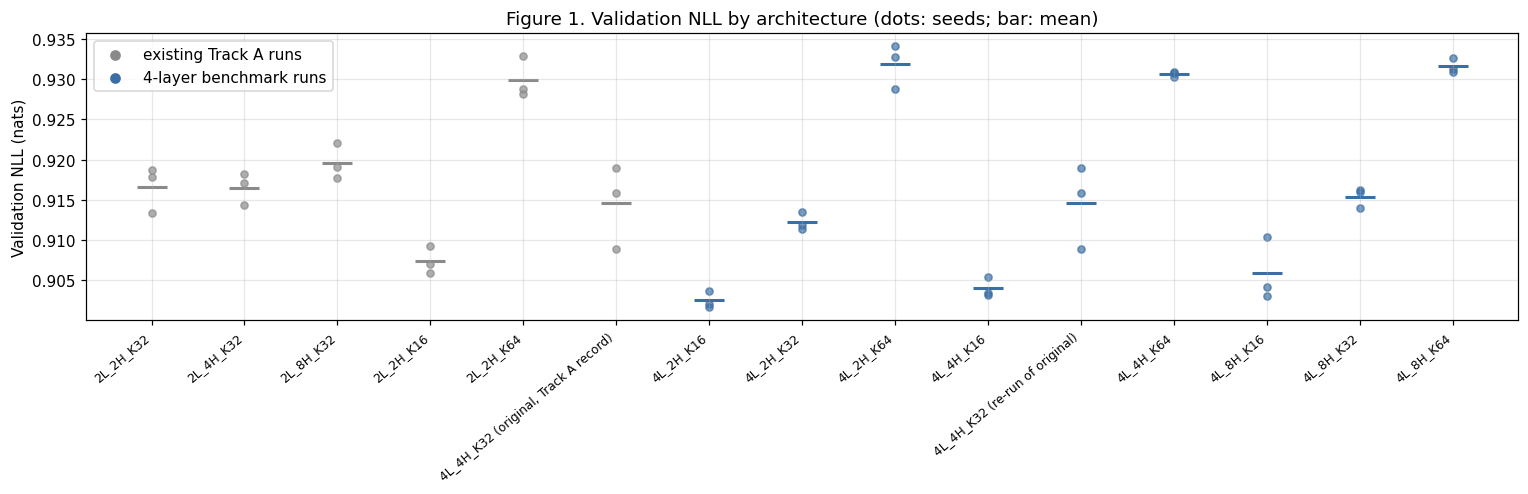

In [13]:
def plot_metric_by_configuration(metric, ylabel, title, file_name):
    """One point per seed and the configuration mean, for every row of the consolidated table except the final run set."""
    plot_rows = consolidated[consolidated["source"] != "Track A notebook 06 (existing, final)"].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(14, 4.6))
    for position, row in plot_rows.iterrows():
        if row["source"] == "4-layer benchmark":
            colour = "#3b6ea5"
            run_dirs = benchmark_runs(row["heads"], row["K"])
        else:
            colour = "#8a8a8a"
            run_dirs = existing_runs(row["layers"], row["heads"], row["K"])
        seed_values = []
        for run_dir in run_dirs:
            seed_values.append(run_record(run_dir, "", "")[metric])
        ax.scatter(np.full(len(seed_values), position), seed_values, color=colour, s=22, alpha=0.7)
        ax.scatter([position], [np.mean(seed_values)], color=colour, marker="_", s=400, linewidths=2)
    ax.set_xticks(range(len(plot_rows)))
    ax.set_xticklabels(plot_rows["configuration"], rotation=40, ha="right", fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.scatter([], [], color="#8a8a8a", label="existing Track A runs")
    ax.scatter([], [], color="#3b6ea5", label="4-layer benchmark runs")
    ax.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / file_name, bbox_inches="tight")
    plt.show()


plot_metric_by_configuration("val_nll", "Validation NLL (nats)", "Figure 1. Validation NLL by architecture (dots: seeds; bar: mean)",
                             "05_4L_fig1_nll_by_architecture.png")

**Figure 1.** Validation NLL of every seed (dots) and the configuration mean (horizontal bar), for the existing Track A screening runs (grey) and the 4-layer benchmark runs (blue). Lower values are better.

The figure is appropriate because it shows the size of the differences between configurations next to the spread between seeds of the same configuration, which is the comparison the decision rule formalises. A difference between two means that is smaller than the spread of the seeds does not support a preference for either configuration. The points group mainly by context length: all K = 16 configurations, at 2 and 4 layers, lie at the bottom of the figure and all K = 64 configurations at the top. The spread between seeds is small compared with the differences between context lengths, but of similar size to the differences between head counts. The figure does not replace the paired bootstrap comparison of Sections 4–5, because it does not show that the configurations are evaluated on the same events.

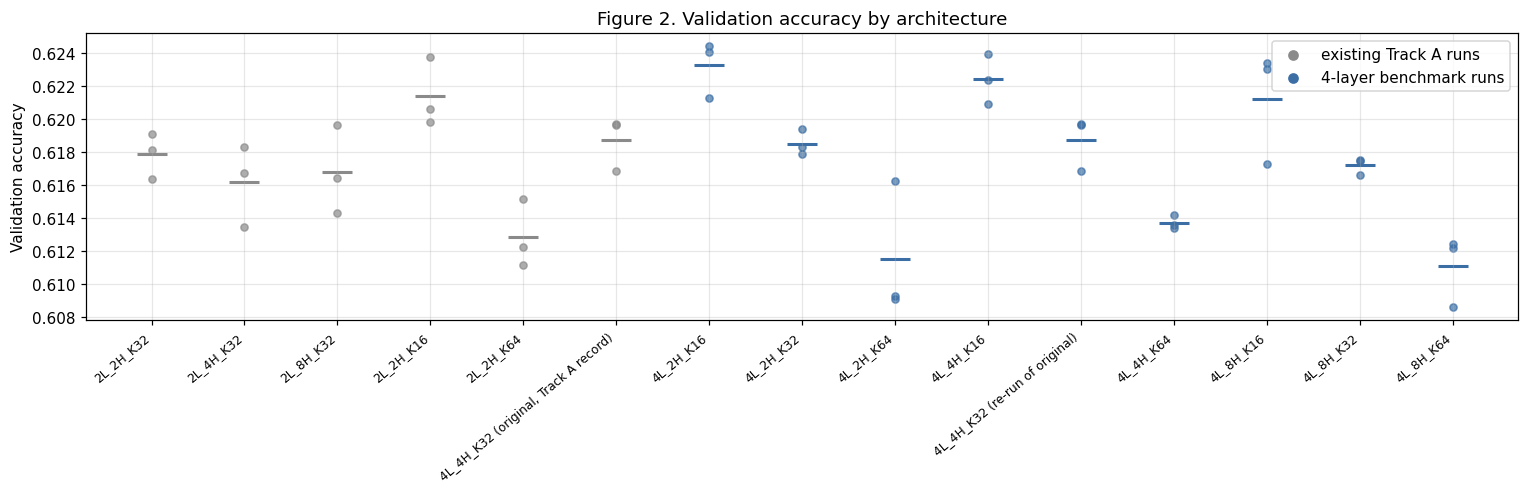

In [14]:
plot_metric_by_configuration("val_accuracy", "Validation accuracy", "Figure 2. Validation accuracy by architecture",
                             "05_4L_fig2_accuracy_by_architecture.png")

**Figure 2.** Validation accuracy of every seed and configuration. Accuracy evaluates only the most probable class, so two models can differ in NLL while having almost identical accuracy. The figure is used to check whether an NLL difference is accompanied by a difference in argmax predictions. Accuracy follows the NLL ordering: the K = 16 configurations reach about 0.621–0.623 and the K = 64 configurations about 0.611–0.614. The differences between head counts at a fixed context length are of the same size as the variation between seeds. The figure does not show performance on rare classes.

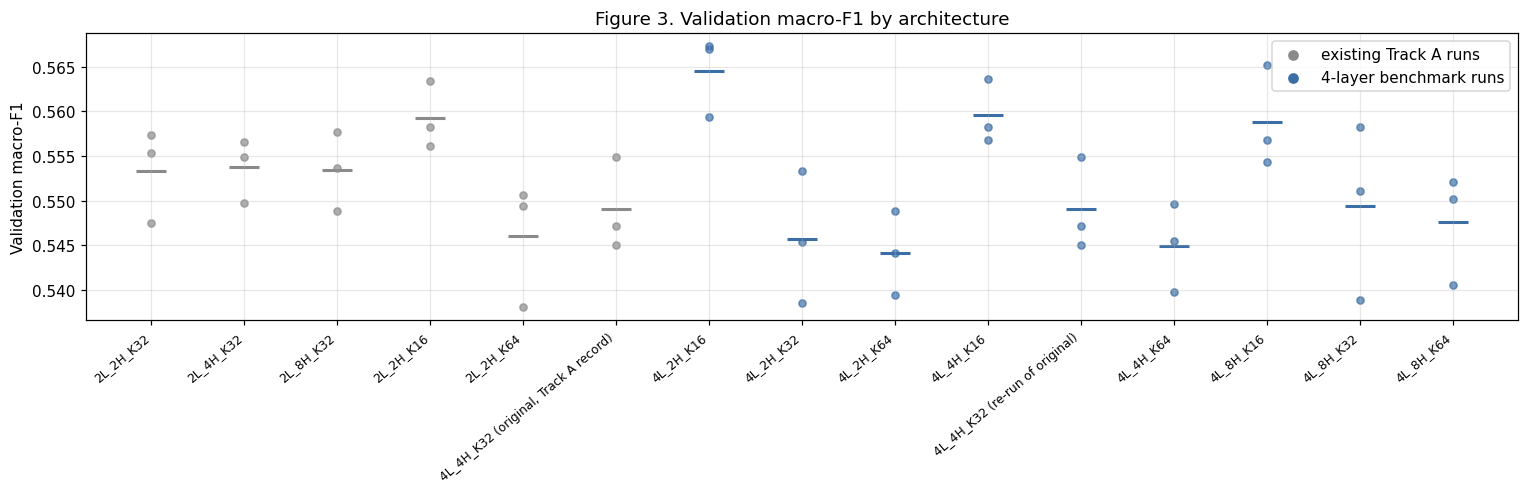

In [15]:
plot_metric_by_configuration("val_macro_f1", "Validation macro-F1", "Figure 3. Validation macro-F1 by architecture",
                             "05_4L_fig3_macro_f1_by_architecture.png")

**Figure 3.** Validation macro-F1 of every seed and configuration. Because each of the 15 classes contributes equally, macro-F1 is sensitive to rare classes such as SHOT, CROSS and DRIBBLE. Macro-F1 is more variable between seeds than NLL, since a few rare-class predictions can change it; small differences in this figure are not interpreted as architectural effects. The K = 16 configurations have the highest macro-F1 (0.559–0.565 at 4 layers, 0.559 for 2L_2H_K16); at K = 32 and K = 64 the values lie between 0.544 and 0.555.

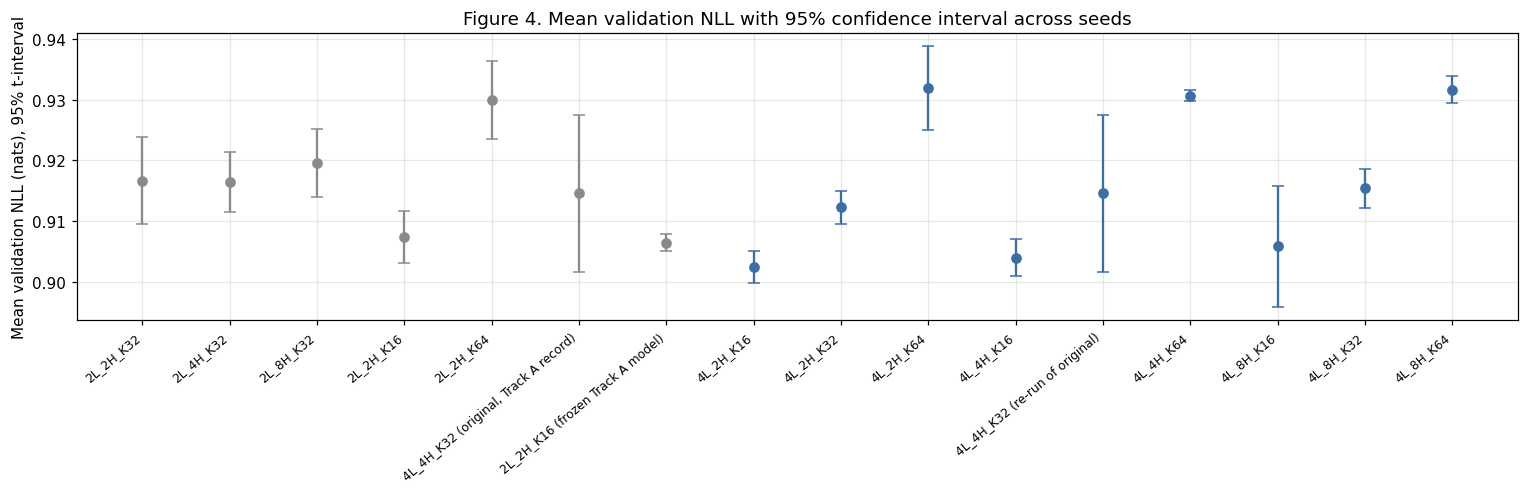

In [16]:
fig, ax = plt.subplots(figsize=(14, 4.6))
plot_rows = consolidated.reset_index(drop=True)
for position, row in plot_rows.iterrows():
    colour = "#3b6ea5" if row["source"] == "4-layer benchmark" else "#8a8a8a"
    lower_error = row["mean val NLL"] - row["NLL 95% CI low"]
    upper_error = row["NLL 95% CI high"] - row["mean val NLL"]
    ax.errorbar(position, row["mean val NLL"], yerr=[[lower_error], [upper_error]], fmt="o", color=colour, capsize=4)
ax.set_xticks(range(len(plot_rows)))
ax.set_xticklabels(plot_rows["configuration"], rotation=40, ha="right", fontsize=8)
ax.set_ylabel("Mean validation NLL (nats), 95% t-interval")
ax.set_title("Figure 4. Mean validation NLL with 95% confidence interval across seeds")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_4L_fig4_nll_confidence_intervals.png", bbox_inches="tight")
plt.show()

**Figure 4.** Mean validation NLL of each configuration with its 95% t-interval across seeds. With three seeds the intervals are wide (the t multiplier is 4.30), so strongly overlapping intervals are expected even for configurations that the paired bootstrap comparison distinguishes. The figure shows the uncertainty due to training variation alone; it does not account for the sampling of validation matches, which the paired comparison of Sections 4–5 includes. Non-overlapping intervals indicate a difference that is large relative to seed variation; overlapping intervals do not establish that two configurations are equivalent. The K = 16 intervals lie below the K = 32 and K = 64 intervals, with the exception of the wide interval of 4L_8H_K16. The original 4L_4H_K32 configuration has the widest interval (0.9017–0.9274), which reflects its larger seed variation.

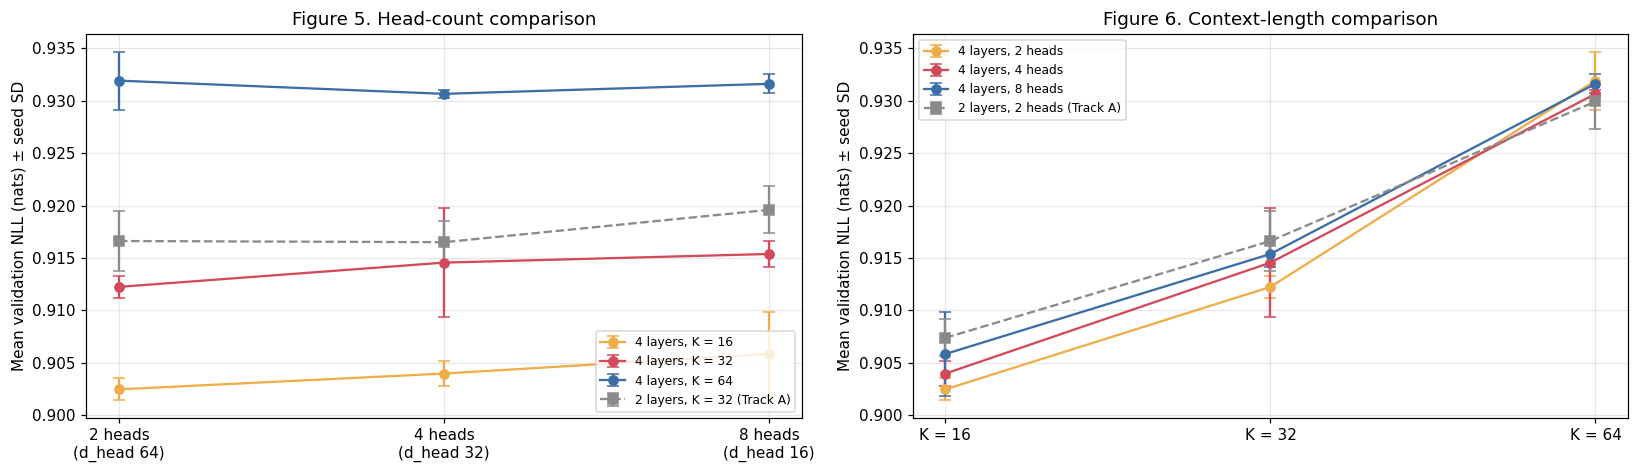

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
colours_by_context = {16: "#edae49", 32: "#d1495b", 64: "#3b6ea5"}
for context_length in GRID_CONTEXT:
    subset = grid_summary[grid_summary["K"] == context_length].sort_values("heads")
    axes[0].errorbar(subset["heads"], subset["mean val NLL"], yerr=subset["NLL SD"], marker="o", capsize=4,
                     color=colours_by_context[context_length], label=f"4 layers, K = {context_length}")
two_layer_heads = consolidated[(consolidated["layers"] == 2) & (consolidated["K"] == 32)
                               & (consolidated["source"] == "Track A notebook 05 (existing)")].sort_values("heads")
if len(two_layer_heads) > 0:
    axes[0].errorbar(two_layer_heads["heads"], two_layer_heads["mean val NLL"], yerr=two_layer_heads["NLL SD"],
                     marker="s", linestyle="--", capsize=4, color="#8a8a8a", label="2 layers, K = 32 (Track A)")
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(GRID_HEADS)
axes[0].set_xticklabels([f"{h} heads\n(d_head {128 // h})" for h in GRID_HEADS])
axes[0].set_ylabel("Mean validation NLL (nats) ± seed SD")
axes[0].set_title("Figure 5. Head-count comparison")
axes[0].legend(fontsize=8)

colours_by_heads = {2: "#edae49", 4: "#d1495b", 8: "#3b6ea5"}
for n_heads in GRID_HEADS:
    subset = grid_summary[grid_summary["heads"] == n_heads].sort_values("K")
    axes[1].errorbar(subset["K"], subset["mean val NLL"], yerr=subset["NLL SD"], marker="o", capsize=4,
                     color=colours_by_heads[n_heads], label=f"4 layers, {n_heads} heads")
two_layer_context = consolidated[(consolidated["layers"] == 2) & (consolidated["heads"] == 2)
                                 & (consolidated["source"] == "Track A notebook 05 (existing)")].sort_values("K")
if len(two_layer_context) > 0:
    axes[1].errorbar(two_layer_context["K"], two_layer_context["mean val NLL"], yerr=two_layer_context["NLL SD"],
                     marker="s", linestyle="--", capsize=4, color="#8a8a8a", label="2 layers, 2 heads (Track A)")
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(GRID_CONTEXT)
axes[1].set_xticklabels([f"K = {k}" for k in GRID_CONTEXT])
axes[1].set_ylabel("Mean validation NLL (nats) ± seed SD")
axes[1].set_title("Figure 6. Context-length comparison")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_4L_fig5_6_heads_and_context.png", bbox_inches="tight")
plt.show()

**Figure 5.** Mean validation NLL as a function of the head count, one line per context length, with the Track A 2-layer head sweep (K = 32) in grey. Parallel lines indicate that the head-count effect does not depend on the context length; crossing lines indicate an interaction. The figure is used together with the two-way analysis of Section 4.5.

**Figure 6.** Mean validation NLL as a function of the context length, one line per head count, with the Track A 2-layer context sweep (2 heads) in grey. The comparison of the grey and coloured lines shows whether the context-length effect observed at 2 layers is also present at 4 layers. In Figure 5 the three 4-layer lines are roughly flat and parallel, with the K = 16 line well below the others, and the 2-layer line at K = 32 lies slightly above the 4-layer K = 32 line. In Figure 6 all lines rise steeply from K = 16 to K = 64 and converge at K = 64, where depth makes no visible difference. The figures show means and seed SDs; they do not by themselves establish that a difference is beyond noise.

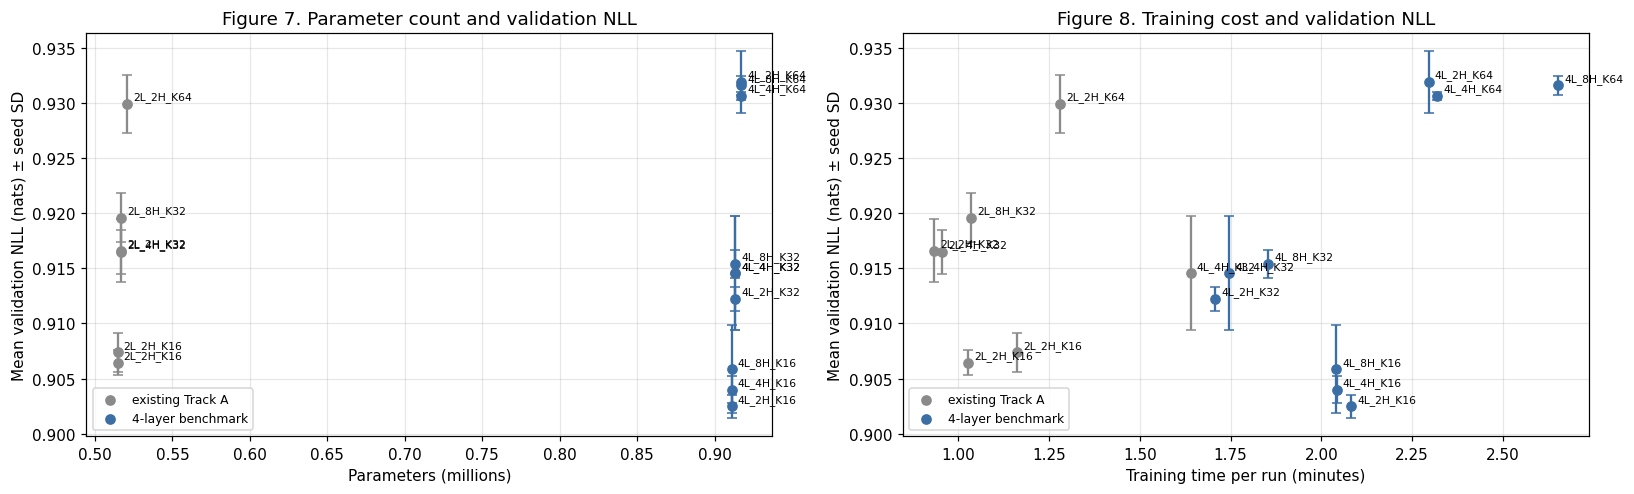

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for _, row in consolidated.iterrows():
    colour = "#3b6ea5" if row["source"] == "4-layer benchmark" else "#8a8a8a"
    axes[0].errorbar(row["parameters"] / 1e6, row["mean val NLL"], yerr=row["NLL SD"], fmt="o", color=colour, capsize=3)
    axes[0].annotate(row["configuration"].split(" ")[0], (row["parameters"] / 1e6, row["mean val NLL"]),
                     textcoords="offset points", xytext=(4, 3), fontsize=7)
    axes[1].errorbar(row["training minutes per run"], row["mean val NLL"], yerr=row["NLL SD"], fmt="o", color=colour, capsize=3)
    axes[1].annotate(row["configuration"].split(" ")[0], (row["training minutes per run"], row["mean val NLL"]),
                     textcoords="offset points", xytext=(4, 3), fontsize=7)
axes[0].set_xlabel("Parameters (millions)")
axes[0].set_ylabel("Mean validation NLL (nats) ± seed SD")
axes[0].set_title("Figure 7. Parameter count and validation NLL")
axes[1].set_xlabel("Training time per run (minutes)")
axes[1].set_ylabel("Mean validation NLL (nats) ± seed SD")
axes[1].set_title("Figure 8. Training cost and validation NLL")
for axis in axes:
    axis.scatter([], [], color="#8a8a8a", label="existing Track A")
    axis.scatter([], [], color="#3b6ea5", label="4-layer benchmark")
    axis.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_4L_fig7_8_parameters_and_cost.png", bbox_inches="tight")
plt.show()

**Figure 7.** Mean validation NLL against parameter count. The 2-layer and 4-layer models form two clusters (approximately 0.52 and 0.91 million parameters); within a depth, the head count leaves the parameter count unchanged and the context length changes it only through the positional embeddings. The figure shows whether the additional parameters of the 4-layer family are associated with lower NLL.

**Figure 8.** Mean validation NLL against training time per run. Training time combines the cost per epoch and the number of epochs before early stopping, and is measured on a shared GPU, so it is an approximate practical cost. Neither figure identifies a cause: parameter count and training time are properties of the configuration, not independent variables of the experiment. The best 4-layer configuration (0.9025) improves on the best 2-layer screening configuration (0.9074) by about 0.005 nats, using about 1.8 times as many parameters and about twice the training time per run. Within each depth, the NLL range spanned by the context lengths is much larger than the change from 2 to 4 layers.

## 8. Mechanistic-interpretability feasibility

The planned mechanistic analysis of the selected model uses attention-pattern analysis, head ablation, activation patching and path patching. The cost and clarity of these analyses depend on the architecture. The table reports, for each 4-layer configuration and for the frozen Track A model:

* **attention heads** — total number of heads (layers × heads), the number of single-head ablations;
* **head-position units** — layers × heads × K, the number of (head, query position) units an exhaustive head-level patching analysis at every position must examine; this quantity is also used to order configurations from simplest to most complex in Section 9;
* **attention entries per window** — layers × heads × K², the number of attention weights stored for one window;
* **layer-position patching sites** — layers × K;
* **head-pair paths** — the number of (sender head, receiver head) pairs across layers, the number of path-patching experiments between heads;
* **activation cache per window** — the residual stream before each layer and after the last layer, all attention patterns and all MLP hidden activations for one window, in 32-bit floats;
* **cache for the validation split** — the same quantity for all evaluation windows of the validation split.

In [19]:
def feasibility(n_layers, n_heads, context_length, parameters):
    d_head = D_MODEL // n_heads
    residual_values = (n_layers + 1) * context_length * D_MODEL
    attention_values = n_layers * n_heads * context_length * context_length
    mlp_values = n_layers * context_length * D_FF
    bytes_per_window = 4 * (residual_values + attention_values + mlp_values)
    validation_windows = len(bundle_for(context_length)["views"]["val"]["windows"])
    head_pairs = 0
    for sender_layer in range(n_layers):
        for receiver_layer in range(sender_layer + 1, n_layers):
            head_pairs += n_heads * n_heads
    return {"configuration": config_id(n_layers, n_heads, context_length), "layers": n_layers, "heads": n_heads,
            "d_head": d_head, "residual width": D_MODEL, "K": context_length, "parameters": parameters,
            "attention heads": n_layers * n_heads, "head-position units": n_layers * n_heads * context_length,
            "attention entries per window": attention_values, "layer-position patching sites": n_layers * context_length,
            "head-pair paths": head_pairs, "cache per window (KB)": bytes_per_window / 1024,
            "validation windows": validation_windows,
            "cache for validation split (GB)": bytes_per_window * validation_windows / 1024 ** 3}


feasibility_rows = []
for _, row in grid_summary.iterrows():
    feasibility_rows.append(feasibility(4, int(row["heads"]), int(row["K"]), int(row["parameters"])))
frozen_parameters = analysis.load_final_results(final_runs[0])["parameter_counts"]["total"] if len(final_runs) > 0 else np.nan
feasibility_rows.append(feasibility(frozen_model["n_layers"], frozen_model["n_heads"], EXISTING_FROZEN["context_length"],
                                    frozen_parameters))
feasibility_rows[-1]["configuration"] = feasibility_rows[-1]["configuration"] + " (frozen Track A)"
feasibility_table = pd.DataFrame(feasibility_rows)
feasibility_table.to_csv(RESULTS_DIR / "05_4L_mi_feasibility.csv", index=False)
feasibility_table.round(3)

,configuration,layers,heads,d_head,residual width,K,parameters,attention heads,head-position units,attention entries per window,layer-position patching sites,head-pair paths,cache per window (KB),validation windows,cache for validation split (GB)
0,4L_2H_K16,4,2,64,128,16,911119,8,128,2048,64,24,176.0,8459,1.420
1,4L_2H_K32,4,2,64,128,32,913167,8,256,8192,128,24,368.0,8319,2.920
2,4L_2H_K64,4,2,64,128,64,917263,8,512,32768,256,24,800.0,8039,6.133
3,4L_4H_K16,4,4,32,128,16,911119,16,256,4096,64,96,184.0,8459,1.484
4,4L_4H_K32,4,4,32,128,32,913167,16,512,16384,128,96,400.0,8319,3.173
5,4L_4H_K64,4,4,32,128,64,917263,16,1024,65536,256,96,928.0,8039,7.115
6,4L_8H_K16,4,8,16,128,16,911119,32,512,8192,64,384,200.0,8459,1.613
7,4L_8H_K32,4,8,16,128,32,913167,32,1024,32768,128,384,464.0,8319,3.681
8,4L_8H_K64,4,8,16,128,64,917263,32,2048,131072,256,384,1184.0,8039,9.077
9,2L_2H_K16 (frozen Track A),2,2,64,128,16,514575,4,64,1024,32,4,92.0,8459,0.742


**Interpretation.** All configurations are small enough for exhaustive single-head ablation and layer-wise patching on a single GPU; the cost differences lie in the number of units that have to be examined and in the size of the stored attention patterns.

* The number of heads multiplies the number of ablations, head-position units and head-pair paths. Eight heads per layer give 32 heads and 384 head-pair paths, against 8 heads and 24 paths for two heads per layer. A larger number of narrower heads (d_head = 16) can make individual heads more specialised, but it also increases the number of components among which a mechanism can be distributed, which makes path-level analysis more expensive and attribution less concentrated.
* The context length enters the attention cache quadratically. K = 64 stores 16 times as many attention weights per window as K = 16, and patching over positions scales linearly with K.
* Depth is fixed at 4 in this benchmark. Four layers allow compositions of attention across three layer boundaries, which is required for mechanistic hypotheses that involve more than one stage of attention-mediated routing (for example, a head that reads context selected by an earlier head); two layers allow only one such composition. This property is shared by all configurations of the grid and distinguishes them from the frozen Track A model.

For the configurations relevant to the selection: 4L_2H_K16 has 8 heads, 128 head-position units, 24 head-pair paths and an activation cache of about 1.4 GB for the validation split. The frozen 2-layer model has 4 heads, 64 units, 4 paths and about 0.7 GB. At the other extreme, 4L_8H_K64 has 32 heads, 2,048 units, 384 paths and about 9.1 GB. All of these are feasible on a single GPU; the 2-head K = 16 configuration is the least expensive of the 4-layer grid by every measure.

These quantities describe the cost of the planned analyses. They do not predict whether a clear mechanism will be found in a given model.

## 9. Selection

The selection distinguishes five questions and answers each with its own evidence. No composite score is used, because the questions weigh different properties and no weighting of them is established by the research specification.

1. **Best predictive 4-layer configuration** — the lowest mean validation NLL, with its comparison against the next configuration.
2. **Most stable 4-layer configuration** — the lowest seed SD of validation NLL. With three seeds the SD itself is imprecise; its 95% confidence interval is computed from the chi-square distribution, and if the intervals overlap for all configurations the stability comparison is reported as inconclusive.
3. **Most MI-accessible 4-layer configuration** — the configuration with the fewest head-position units (Section 8), irrespective of predictive performance.
4. **Smallest adequate 4-layer configuration** — the Track A rule "smallest configuration within noise of the best", with configurations ordered from simplest to most complex by the number of head-position units (layers × heads × K), ties broken by parameter count. The ordering is a convention of this benchmark.
5. **Selected configuration for final evaluation (best 4-layer model)** — the smallest adequate configuration (question 4).

A sixth question is answered separately: **whether the validation evidence supports replacing the existing 2-layer Track A model with the selected 4-layer configuration.** The best 4-layer model and a replacement for the existing model are different questions. The first compares configurations within the 4-layer family. The second compares the selected 4-layer configuration with the frozen Track A model under the same rule and does not change the frozen Track A model; the replacement decision is not made in this benchmark.

In [20]:
selection_rows = []
for _, row in grid_summary.iterrows():
    n_heads = int(row["heads"])
    context_length = int(row["K"])
    n_seeds = int(row["seeds"])
    sd = row["NLL SD"]
    sd_low = np.sqrt((n_seeds - 1) * sd ** 2 / stats.chi2.ppf(0.975, n_seeds - 1))
    sd_high = np.sqrt((n_seeds - 1) * sd ** 2 / stats.chi2.ppf(0.025, n_seeds - 1))
    selection_rows.append({"configuration": config_id(4, n_heads, context_length), "heads": n_heads, "K": context_length,
                           "parameters": int(row["parameters"]), "head-position units": 4 * n_heads * context_length,
                           "mean val NLL": row["mean val NLL"], "NLL SD": sd, "SD 95% CI low": sd_low,
                           "SD 95% CI high": sd_high})
selection_table = pd.DataFrame(selection_rows)

best_row = selection_table.loc[selection_table["mean val NLL"].idxmin()]
runner_up = selection_table.drop(index=selection_table["mean val NLL"].idxmin()).sort_values("mean val NLL").iloc[0]
best_versus_runner_up = compare_pair(best_row["configuration"], benchmark_runs(best_row["heads"], best_row["K"]),
                                     runner_up["configuration"], benchmark_runs(runner_up["heads"], runner_up["K"]))

stable_row = selection_table.loc[selection_table["NLL SD"].idxmin()]
other_sds = selection_table.drop(index=selection_table["NLL SD"].idxmin())["NLL SD"]
stability_conclusive = bool(stable_row["SD 95% CI high"] < other_sds.max())

accessible_row = selection_table.sort_values(["head-position units", "parameters"]).iloc[0]

ordered = selection_table.sort_values(["head-position units", "parameters"])
candidates = []
for _, row in ordered.iterrows():
    candidates.append((row["configuration"], benchmark_runs(row["heads"], row["K"])))
selected_label, adequacy_table = analysis.smallest_within_noise(candidates, targets, match_ids)
selected_row = selection_table[selection_table["configuration"] == selected_label].iloc[0]
adequacy_table.to_csv(RESULTS_DIR / "05_4L_smallest_adequate.csv")
print("Order from simplest to most complex (head-position units, then parameters):", list(ordered["configuration"]))
adequacy_table

Order from simplest to most complex (head-position units, then parameters): ['4L_2H_K16', '4L_4H_K16', '4L_2H_K32', '4L_8H_K16', '4L_4H_K32', '4L_2H_K64', '4L_8H_K32', '4L_4H_K64', '4L_8H_K64']


,mean val NLL,is best,best beats it beyond noise,best - candidate (CI),seeds separated
candidate,,,,,
4L_2H_K16,0.9025,True,False,NaN,NaN
4L_4H_K16,0.9040,False,False,"-0.0015 [-0.0035, +0.0004]",False
4L_2H_K32,0.9122,False,True,"-0.0098 [-0.0123, -0.0072]",True
4L_8H_K16,0.9058,False,False,"-0.0034 [-0.0055, -0.0013]",False
4L_4H_K32,0.9146,False,True,"-0.0121 [-0.0147, -0.0095]",True
4L_2H_K64,0.9319,False,True,"-0.0294 [-0.0329, -0.0261]",True
4L_8H_K32,0.9154,False,True,"-0.0129 [-0.0159, -0.0099]",True
4L_4H_K64,0.9307,False,True,"-0.0282 [-0.0308, -0.0254]",True
4L_8H_K64,0.9316,False,True,"-0.0291 [-0.0330, -0.0256]",True


**Reading the table.** The configuration marked "is best" has the lowest mean validation NLL. Each other configuration is compared with it under the decision rule; "best beats it beyond noise" is True only when both the bootstrap interval and the seed separation criterion hold. The selected configuration is the first one in the order from simplest to most complex that the best configuration does not beat beyond noise.

**Result.** The configuration with the lowest mean validation NLL, 4L_2H_K16 (0.9025), is also the first in the simplicity order, so it is selected. The other two K = 16 configurations are not beaten beyond noise (4L_4H_K16 by 0.0015, interval including zero; 4L_8H_K16 by 0.0034, seeds overlapping). All K = 32 and K = 64 configurations are beaten beyond noise, by 0.0098 to 0.0294 nats.

In [24]:
selected_runs = benchmark_runs(int(selected_row["heads"]), int(selected_row["K"]))
frozen_label = config_id(frozen_model["n_layers"], frozen_model["n_heads"], EXISTING_FROZEN["context_length"])
frozen_screening_runs = existing_runs(frozen_model["n_layers"], frozen_model["n_heads"], EXISTING_FROZEN["context_length"])
if len(frozen_screening_runs) > 0:
    replacement_comparison = compare_pair(selected_label, selected_runs, frozen_label + " (frozen Track A, seeds 0-2)",
                                          frozen_screening_runs)
    if replacement_comparison["lower"] == selected_label and replacement_comparison["a_better_beyond_noise"]:
        replacement_statement = ("The selected 4-layer configuration has lower validation NLL than the frozen Track A "
                                 "configuration beyond noise. The validation evidence is consistent with considering a "
                                 "replacement; needs a clear decision of choice")
    elif replacement_comparison["lower"] == selected_label:
        replacement_statement = ("The selected 4-layer configuration has lower mean validation NLL than the frozen Track A "
                                 "configuration, but the difference does not meet the decision rule. The validation "
                                 "evidence is insufficient to support replacing the existing model on predictive grounds.")
    else:
        replacement_statement = ("The frozen Track A configuration has lower mean validation NLL than the selected "
                                 "4-layer configuration. The validation evidence does not support replacing the "
                                 "existing model on predictive grounds.")
    replacement_text = describe(replacement_comparison)
else:
    replacement_comparison = None
    replacement_statement = "Screening runs of the frozen Track A configuration were not found; the comparison is not available."
    replacement_text = ""
print(replacement_text)
print(replacement_statement)

4L_2H_K16 had a lower mean validation NLL than 2L_2H_K16 (frozen Track A, seeds 0-2) by 0.0049 nats (95% bootstrap CI of the gap 0.0025 to 0.0073). Both criteria of the decision rule were met, so the difference is treated as beyond noise.
The selected 4-layer configuration has lower validation NLL than the frozen Track A configuration beyond noise. The validation evidence is consistent with considering a replacement; needs a clear decision of choice


The replacement comparison uses the screening seeds (0–2) of both configurations, so that both arms have the same number of seeds and the same seed values. The frozen Track A model's final seeds (100–104) are not used here, because the benchmark's selected configuration has not yet been trained on those seeds.

**Result.** On the matched screening seeds, 4L_2H_K16 has lower validation NLL than the frozen configuration 2L_2H_K16 by 0.0049 nats (95% CI 0.0025 to 0.0073), with complete seed separation. The difference meets the decision rule. It is about half the size of the difference between K = 16 and K = 32.

## 10. Architecture-selection report

In [22]:
def summary_line(row):
    return (f"mean validation NLL {row['mean val NLL']:.4f} (SD {row['NLL SD']:.4f}, seeds {row['per-seed val NLL']}), "
            f"accuracy {row['val accuracy']:.4f}, macro-F1 {row['val macro-F1']:.4f}, top-3 {row['val top-3']:.4f}, "
            f"top-5 {row['val top-5']:.4f}, ECE {row['val ECE']:.4f}, {int(row['parameters']):,} parameters")


existing_two_layer = consolidated[(consolidated["layers"] == 2) & (consolidated["source"] == "Track A notebook 05 (existing)")]
report_lines = []
if len(existing_two_layer) > 0:
    best_two = existing_two_layer.loc[existing_two_layer["mean val NLL"].idxmin()]
    report_lines.append(("Existing best 2-layer configuration (Track A screening)", f"{best_two['configuration']}: {summary_line(best_two)}"))
original_record = consolidated[consolidated["configuration"].str.contains("original, Track A record")]
rerun_record = grid_summary[grid_summary["configuration"].str.contains("re-run")].iloc[0]
if len(original_record) > 0:
    report_lines.append(("Original 4L4H configuration (Track A notebook 05 record)",
                         f"{summary_line(original_record.iloc[0])}. Reported for reference; not part of the benchmark comparisons."))
report_lines.append(("Original 4L4H configuration (benchmark reproducibility re-run)",
                     f"{summary_line(rerun_record)}. This re-run is used in all benchmark comparisons."))

head_text = []
for context_length in GRID_CONTEXT:
    subset = grid_summary[grid_summary["K"] == context_length].sort_values("heads")
    values = ", ".join(f"{int(h)}H {v:.4f}" for h, v in zip(subset["heads"], subset["mean val NLL"]))
    head_text.append(f"K={context_length}: {values}")
report_lines.append(("New 4-layer head sweep (mean validation NLL)", " | ".join(head_text)))
context_text = []
for n_heads in GRID_HEADS:
    subset = grid_summary[grid_summary["heads"] == n_heads].sort_values("K")
    values = ", ".join(f"K{int(k)} {v:.4f}" for k, v in zip(subset["K"], subset["mean val NLL"]))
    context_text.append(f"{n_heads} heads: {values}")
report_lines.append(("New 4-layer context sweep (mean validation NLL)", " | ".join(context_text)))
report_lines.append(("Best predictive 4-layer configuration",
                     f"{best_row['configuration']} (mean {best_row['mean val NLL']:.4f}). {describe(best_versus_runner_up)}"))
stability_note = ("The SD confidence intervals separate this configuration from at least one other."
                  if stability_conclusive else
                  "The 95% confidence intervals of the SDs overlap for all configurations, so the stability comparison is inconclusive.")
report_lines.append(("Most stable 4-layer configuration",
                     f"{stable_row['configuration']} (seed SD {stable_row['NLL SD']:.4f}, 95% CI {stable_row['SD 95% CI low']:.4f}"
                     f" to {stable_row['SD 95% CI high']:.4f}). {stability_note}"))
report_lines.append(("Most MI-accessible 4-layer configuration",
                     f"{accessible_row['configuration']} ({int(accessible_row['head-position units'])} head-position units, "
                     f"{4 * int(accessible_row['heads'])} attention heads); chosen on analysis cost only."))
report_lines.append(("Smallest adequate 4-layer configuration",
                     f"{selected_label}: first configuration in the order by head-position units that the best "
                     f"configuration does not beat beyond noise (ordering PROVISIONAL, requires supervisor approval)."))
report_lines.append(("Selected configuration for final evaluation (best 4-layer model)", selected_label))
report_lines.append(("Replacement for the existing 2-layer Track A model", f"{replacement_text} {replacement_statement}"))

for heading, text in report_lines:
    print(heading)
    print("    " + text)
    print()
training.save_json(RESULTS_DIR / "05_4L_selection_report.json", {"report": report_lines, "run_mode": RUN_MODE})

Existing best 2-layer configuration (Track A screening)
    2L_2H_K16: mean validation NLL 0.9074 (SD 0.0017, seeds [0.907, 0.9059, 0.9093]), accuracy 0.6214, macro-F1 0.5593, top-3 0.9474, top-5 0.9942, ECE 0.0205, 514,575 parameters

Original 4L4H configuration (Track A notebook 05 record)
    mean validation NLL 0.9146 (SD 0.0052, seeds [0.9089, 0.9158, 0.919]), accuracy 0.6187, macro-F1 0.5490, top-3 0.9465, top-5 0.9942, ECE 0.0257, 913,167 parameters. Reported for reference; not part of the benchmark comparisons.

Original 4L4H configuration (benchmark reproducibility re-run)
    mean validation NLL 0.9146 (SD 0.0052, seeds [0.9089, 0.9158, 0.919]), accuracy 0.6187, macro-F1 0.5490, top-3 0.9465, top-5 0.9942, ECE 0.0257, 913,167 parameters. This re-run is used in all benchmark comparisons.

New 4-layer head sweep (mean validation NLL)
    K=16: 2H 0.9025, 4H 0.9040, 8H 0.9058 | K=32: 2H 0.9122, 4H 0.9146, 8H 0.9154 | K=64: 2H 0.9319, 4H 0.9307, 8H 0.9316

New 4-layer context swe

**How the report is to be read.**

* **Best predictive and selected configuration.** 4L_2H_K16 has the lowest mean validation NLL of the grid and is also the simplest configuration by the head-position count. The best predictive, smallest adequate and most MI-accessible configurations therefore coincide, and no trade-off between them is required.
* **Stability.** The lowest seed SD belongs to 4L_4H_K64 (0.0004), one of the configurations with the highest NLL. Low variation at a worse NLL is not a reason to prefer a configuration; the selected configuration has a seed SD of 0.0010, which is among the lowest in the grid.
* **Best 4-layer model versus replacement of the Track A model.** The selection answers which 4-layer configuration is best. The replacement statement answers a different question: whether the validation evidence favours the selected 4-layer model over the frozen 2-layer model. On validation it does, by 0.0049 nats on matched seeds. This does not by itself decide the replacement: the gain is small relative to the context-length effect, it doubles the number of layers and nearly doubles the parameter count, and the mechanistic considerations of Section 8 (more attention compositions, 8 instead of 4 heads) are not weighed against predictive performance by any agreed criterion. The final comparison on test is reported in benchmark notebook 06.

## 11. Freezing the benchmark configuration

The selected configuration and the evidence for it are recorded before any test data is used. The test evaluation in benchmark notebook 06 is carried out only for this recorded configuration.

In [23]:
frozen_benchmark = {
    "encoding": ENCODING,
    "possession_features": POSSESSION_FEATURES,
    "context_length": int(selected_row["K"]),
    "stride": STRIDE,
    "model": {"n_layers": 4, "n_heads": int(selected_row["heads"]), "d_model": D_MODEL, "d_ff": D_FF},
    "training": dict(EXISTING_FROZEN["training"]),
    "selected_configuration": selected_label,
    "best_predictive_configuration": best_row["configuration"],
    "most_stable_configuration": stable_row["configuration"],
    "stability_comparison_conclusive": stability_conclusive,
    "most_mi_accessible_configuration": accessible_row["configuration"],
    "selection_rule": ("smallest configuration within noise of the best validation NLL (Track A rule, PROVISIONAL); "
                       "order by head-position units = layers x heads x K, ties by parameter count (PROVISIONAL)"),
    "replacement_assessment": replacement_statement,
    "replacement_decision": "not decided by this benchmark; left to the supervisor",
    "screening_seeds": SCREENING_SEEDS,
    "dataset_sha256": json.load(open(ARTIFACTS_DIR / "dataset_hash.json"))["sha256"],
    "run_mode": RUN_MODE,
    "frozen_at": pd.Timestamp.now(tz="UTC").isoformat(),
}
frozen_path = CONFIG_DIR / "frozen_config.json"
comparable_keys = ["encoding", "possession_features", "context_length", "model", "training"]
if frozen_path.exists():
    with open(frozen_path) as handle:
        existing_benchmark = json.load(handle)
    for key in comparable_keys:
        if existing_benchmark[key] != frozen_benchmark[key]:
            raise RuntimeError("A different frozen benchmark configuration already exists; it is not overwritten.")
    print("The frozen benchmark configuration already exists and matches; it is kept unchanged.")
else:
    training.save_json(frozen_path, frozen_benchmark)
    print("Benchmark configuration frozen:", frozen_path)
print(json.dumps({key: frozen_benchmark[key] for key in ["selected_configuration", "context_length", "model"]}, indent=2))

Benchmark configuration frozen: /content/drive/MyDrive/soccer_mi/track_a/benchmarks/track_a_4layer/config/frozen_config.json
{
  "selected_configuration": "4L_2H_K16",
  "context_length": 16,
  "model": {
    "n_layers": 4,
    "n_heads": 2,
    "d_model": 128,
    "d_ff": 512
  }
}


## 12. Limitations

* **Seeds.** Three seeds per configuration give a coarse estimate of training variation; the stability comparison in particular is imprecise.
* **Inherited hyperparameters.** The learning rate and weight decay were selected on 4L × 4H × K32 with encoding T100. Configurations that would prefer other values may be disadvantaged; a per-configuration search was excluded to keep the comparison restricted to the architecture.
* **Simplicity order.** The order by head-position units is a proposal of this benchmark. A different order (for example by parameter count alone) can change the "smallest adequate" configuration when several configurations are within noise of the best.
* **Decision rule.** The Track A rule is a convention of this study and applies no correction for the number of comparisons.
* **Scope.** Depth is fixed at 4; d_model and d_ff are fixed. The results do not extend to other widths.
* **Validation only.** Every statement in this notebook refers to the validation split. The test evaluation in benchmark notebook 06 is not used to revise the selection.